# ILLM Lab 3 — BPE vs WordPiece on Hindi (IndicCorp v2)

Run cells top to bottom on **Kaggle** (Settings → Internet: ON, Accelerator: not required, CPU is enough).

Steps:
1. Load `ai4bharat/IndicCorpV2` (Hindi), sentence-tokenize paragraphs.
2. Build train / dev(1000) / test(1000) splits, dev & test stratified by sentence length.
3. Train BPE and WordPiece tokenizers.
4. Q3: effect of **training-data size** (100k / 300k / 500k / 1M sentences) on tokenization.
5. Q4: effect of **vocabulary size** (20k / 30k / 50k) on tokenization.


In [1]:
!pip install -q -U datasets tokenizers pandas matplotlib tqdm

In [2]:
import os, re, json, random, gc
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42)

WORK_DIR = "/kaggle/working"
os.makedirs(WORK_DIR, exist_ok=True)

LANG = "hin_Deva"           # Hindi split in IndicCorpV2
DEV_SIZE = 1000
TEST_SIZE = 1000

# how many raw sentences to collect before splitting.
# must comfortably cover the biggest training size (1,000,000) + dev + test + buffer
TARGET_POOL_SIZE = 1_150_000

TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]

DEFAULT_VOCAB_FOR_SIZE_EXPT = 30_000          # used while varying training size (Q3)
DEFAULT_TRAIN_FOR_VOCAB_EXPT = 500_000        # used while varying vocab size (Q4)


## 1. Load IndicCorpV2 (Hindi) and sentence-tokenize

We stream the dataset (it is huge — 275GB across all languages) so we never download more than we need. Each row is a *paragraph*; we split paragraphs into sentences using Hindi sentence-final punctuation (`।`, `॥`, `?`, `!`, `.`).

In [3]:
from datasets import load_dataset

# Devanagari danda (।), double danda (॥) and standard punctuation mark sentence ends.
_SENT_END = re.compile(r'(?<=[।॥!?.])\s+')
_WS = re.compile(r'\s+')

def sentence_tokenize(paragraph: str):
    paragraph = paragraph.strip()
    if not paragraph:
        return []
    parts = _SENT_END.split(paragraph)
    sents = []
    for s in parts:
        s = _WS.sub(' ', s).strip()
        # keep reasonably sized sentences (drop noise / boilerplate)
        n_words = len(s.split())
        if 3 <= n_words <= 100:
            sents.append(s)
    return sents

ds = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split=LANG, streaming=True)

sentences = []
seen = set()
pbar = tqdm(total=TARGET_POOL_SIZE, desc="Collecting Hindi sentences")
for row in ds:
    text = row.get("text", "")
    for sent in sentence_tokenize(text):
        if sent in seen:          # cheap de-dup
            continue
        seen.add(sent)
        sentences.append(sent)
        pbar.update(1)
        if len(sentences) >= TARGET_POOL_SIZE:
            break
    if len(sentences) >= TARGET_POOL_SIZE:
        break
pbar.close()
del seen
gc.collect()

print(f"Collected {len(sentences):,} sentences")
print("Example:", sentences[0])


Collected 1,150,000 sentences
Example: लोगों को बिलों संबंधी सुविधा देना ही उनका काम


## 2. Train / Dev / Test split

Dev and test (1000 sentences each) are drawn so their **length distribution differs from each other and is not just a random sample of similar-length sentences** — we bucket sentences by word-length and sample proportionally across *all* buckets, and additionally send alternating picks from each bucket to dev vs. test so the two sets don't end up looking the same.

train pool: 1,148,001 | dev: 1000 | test: 999


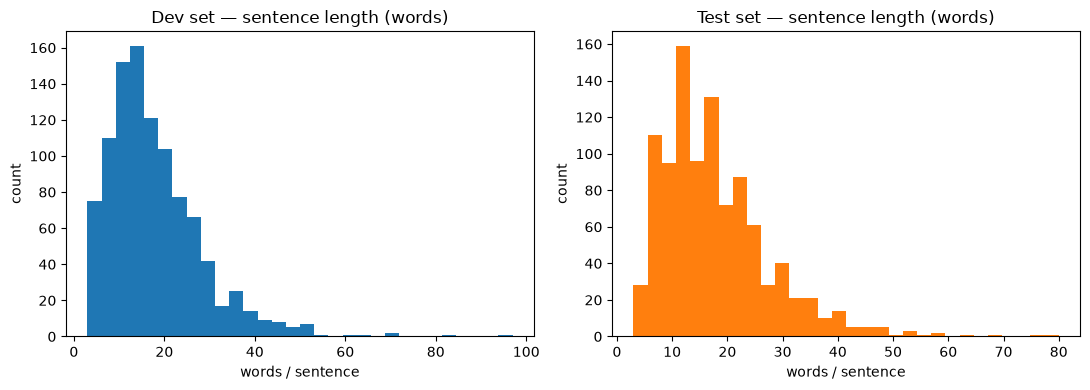

True

In [4]:
lengths = [len(s.split()) for s in sentences]
df_all = pd.DataFrame({"sentence": sentences, "length": lengths})

# bucket by word length (deciles) so we sample across the whole length range
df_all["bucket"] = pd.qcut(df_all["length"], q=10, duplicates="drop")

dev_idx, test_idx = [], []
rng = random.Random(42)

for bucket, grp in df_all.groupby("bucket", observed=True):
    idxs = grp.index.tolist()
    rng.shuffle(idxs)
    n_take = max(2, round(len(idxs) / len(df_all) * (DEV_SIZE + TEST_SIZE)))
    take = idxs[:n_take]
    # alternate assignment -> dev/test end up with different sentences,
    # but both still span the full length distribution
    for i, ix in enumerate(take):
        if i % 2 == 0:
            dev_idx.append(ix)
        else:
            test_idx.append(ix)

rng.shuffle(dev_idx); rng.shuffle(test_idx)
dev_idx = dev_idx[:DEV_SIZE]
test_idx = test_idx[:TEST_SIZE]

held_out = set(dev_idx) | set(test_idx)
train_pool_idx = [i for i in df_all.index if i not in held_out]

dev_sentences = df_all.loc[dev_idx, "sentence"].tolist()
test_sentences = df_all.loc[test_idx, "sentence"].tolist()
train_pool = df_all.loc[train_pool_idx, "sentence"].tolist()
rng.shuffle(train_pool)

print(f"train pool: {len(train_pool):,} | dev: {len(dev_sentences)} | test: {len(test_sentences)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df_all.loc[dev_idx, "length"], bins=30, color="tab:blue")
ax[0].set_title("Dev set — sentence length (words)")
ax[1].hist(df_all.loc[test_idx, "length"], bins=30, color="tab:orange")
ax[1].set_title("Test set — sentence length (words)")
for a in ax:
    a.set_xlabel("words / sentence"); a.set_ylabel("count")
plt.tight_layout(); plt.show()

# persist splits to disk
with open(f"{WORK_DIR}/dev.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(dev_sentences))
with open(f"{WORK_DIR}/test.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(test_sentences))
with open(f"{WORK_DIR}/train_pool.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(train_pool))

max(TRAIN_SIZES) <= len(train_pool) or print("WARNING: not enough sentences for the largest training size — reduce TARGET_POOL_SIZE need or TRAIN_SIZES")


## 3. BPE and WordPiece training/tokenization functions

Both are trained from scratch with `tokenizers` (Rust-backed, fast), word-level pre-tokenization (whitespace split) so tokens are Hindi word-pieces rather than raw bytes.

In [5]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers

SPECIAL_TOKENS = ["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]

def train_bpe(train_sentences, vocab_size):
    tok = Tokenizer(models.BPE(unk_token="[UNK]"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=2,
                                   special_tokens=SPECIAL_TOKENS)
    tok.train_from_iterator(train_sentences, trainer=trainer)
    return tok

def train_wordpiece(train_sentences, vocab_size):
    tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.WordPieceTrainer(vocab_size=vocab_size, min_frequency=2,
                                         special_tokens=SPECIAL_TOKENS)
    tok.train_from_iterator(train_sentences, trainer=trainer)
    return tok

def evaluate(tok, sentences):
    """Return summary stats of a trained tokenizer on a list of sentences."""
    n_tok, n_words, n_unk, tok_lens = 0, 0, 0, []
    for s in sentences:
        enc = tok.encode(s)
        ids, toks = enc.ids, enc.tokens
        n_tok += len(toks)
        n_words += len(s.split())
        n_unk += sum(1 for t in toks if t == "[UNK]")
        tok_lens.extend(len(t) for t in toks if t not in SPECIAL_TOKENS)
    return {
        "vocab_size_actual": tok.get_vocab_size(),
        "avg_tokens_per_sentence": n_tok / len(sentences),
        "avg_tokens_per_word": n_tok / n_words,
        "avg_token_char_len": sum(tok_lens) / max(1, len(tok_lens)),
        "unk_rate_%": 100 * n_unk / n_tok,
    }


## Q3. Effect of training-data size on tokenization

Vocab size fixed at 30,000; training corpus size varies: 100k / 300k / 500k / 1M sentences.

In [6]:
results_size = []
for n in TRAIN_SIZES:
    subset = train_pool[:n]
    bpe_tok = train_bpe(subset, DEFAULT_VOCAB_FOR_SIZE_EXPT)
    wp_tok = train_wordpiece(subset, DEFAULT_VOCAB_FOR_SIZE_EXPT)

    for name, tok in [("BPE", bpe_tok), ("WordPiece", wp_tok)]:
        stats = evaluate(tok, dev_sentences + test_sentences)
        stats.update({"train_size": n, "algorithm": name})
        results_size.append(stats)

    bpe_tok.save(f"{WORK_DIR}/bpe_trainsize_{n}.json")
    wp_tok.save(f"{WORK_DIR}/wordpiece_trainsize_{n}.json")
    print(f"done: train_size={n:,}")

df_size = pd.DataFrame(results_size)[
    ["algorithm", "train_size", "vocab_size_actual", "avg_tokens_per_sentence",
     "avg_tokens_per_word", "avg_token_char_len", "unk_rate_%"]
]
df_size








done: train_size=100,000






done: train_size=300,000






done: train_size=500,000






done: train_size=1,000,000


,algorithm,train_size,vocab_size_actual,avg_tokens_per_sentence,avg_tokens_per_word,avg_token_char_len,unk_rate_%
0,BPE,100000,30000,20.988494,1.171661,3.519080,0.002383
1,WordPiece,100000,30000,21.165583,1.181547,3.624123,0.002364
2,BPE,300000,30000,20.939970,1.168952,3.527235,0.002389
3,WordPiece,300000,30000,21.123562,1.179201,3.627353,0.002368
4,BPE,500000,30000,20.944472,1.169203,3.526477,0.002388
5,WordPiece,500000,30000,21.126563,1.179368,3.627122,0.002368
6,BPE,1000000,30000,20.938969,1.168896,3.527343,0.000000
7,WordPiece,1000000,30000,21.132066,1.179676,3.626636,0.000000


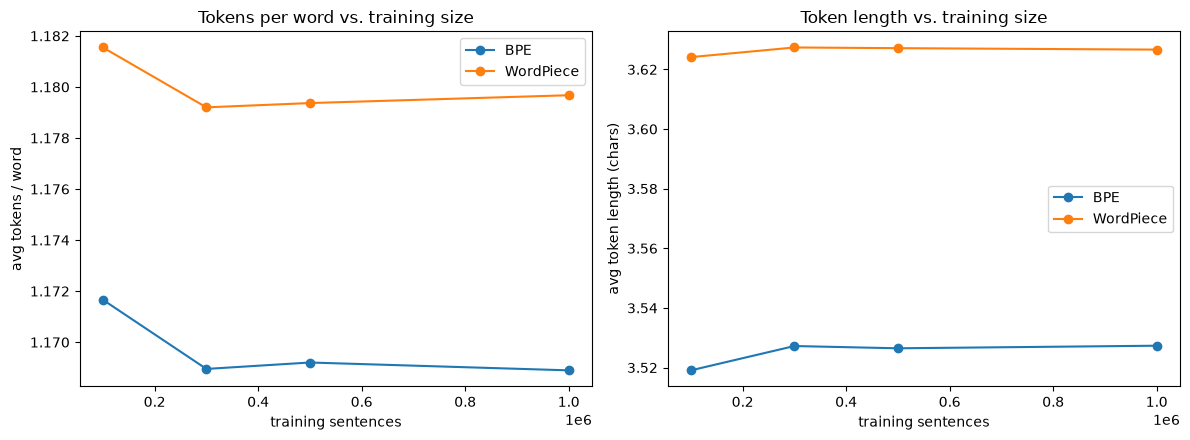

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, grp in df_size.groupby("algorithm"):
    ax[0].plot(grp["train_size"], grp["avg_tokens_per_word"], marker="o", label=name)
    ax[1].plot(grp["train_size"], grp["avg_token_char_len"], marker="o", label=name)
ax[0].set_xlabel("training sentences"); ax[0].set_ylabel("avg tokens / word")
ax[0].set_title("Tokens per word vs. training size"); ax[0].legend()
ax[1].set_xlabel("training sentences"); ax[1].set_ylabel("avg token length (chars)")
ax[1].set_title("Token length vs. training size"); ax[1].legend()
plt.tight_layout(); plt.show()

df_size.to_csv(f"{WORK_DIR}/results_training_size.csv", index=False)


## Q4. Effect of vocabulary size on tokenization

Training corpus fixed at 500,000 sentences; vocab size varies: 20k / 30k / 50k.

In [8]:
results_vocab = []
subset = train_pool[:DEFAULT_TRAIN_FOR_VOCAB_EXPT]

for v in VOCAB_SIZES:
    bpe_tok = train_bpe(subset, v)
    wp_tok = train_wordpiece(subset, v)

    for name, tok in [("BPE", bpe_tok), ("WordPiece", wp_tok)]:
        stats = evaluate(tok, dev_sentences + test_sentences)
        stats.update({"vocab_size_target": v, "algorithm": name})
        results_vocab.append(stats)

    bpe_tok.save(f"{WORK_DIR}/bpe_vocab_{v}.json")
    wp_tok.save(f"{WORK_DIR}/wordpiece_vocab_{v}.json")
    print(f"done: vocab_size={v:,}")

df_vocab = pd.DataFrame(results_vocab)[
    ["algorithm", "vocab_size_target", "vocab_size_actual", "avg_tokens_per_sentence",
     "avg_tokens_per_word", "avg_token_char_len", "unk_rate_%"]
]
df_vocab








done: vocab_size=20,000






done: vocab_size=30,000






done: vocab_size=50,000


,algorithm,vocab_size_target,vocab_size_actual,avg_tokens_per_sentence,avg_tokens_per_word,avg_token_char_len,unk_rate_%
0,BPE,20000,20000,21.483242,1.199280,3.438036,0.002329
1,WordPiece,20000,20000,21.802401,1.217096,3.576683,0.002294
2,BPE,30000,30000,20.944472,1.169203,3.526477,0.002388
3,WordPiece,30000,30000,21.126563,1.179368,3.627122,0.002368
4,BPE,50000,50000,20.522761,1.145662,3.598942,0.002438
5,WordPiece,50000,50000,20.612306,1.150660,3.667718,0.002427


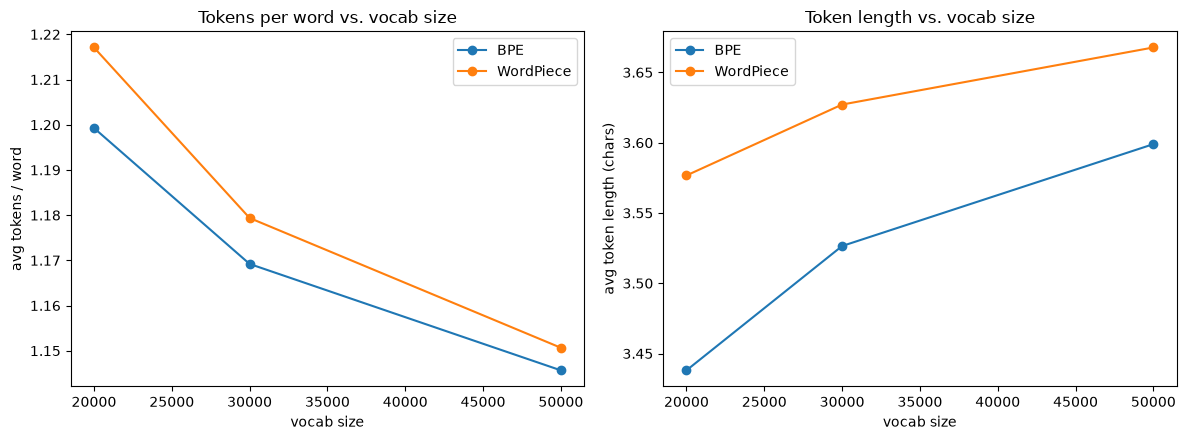

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, grp in df_vocab.groupby("algorithm"):
    ax[0].plot(grp["vocab_size_target"], grp["avg_tokens_per_word"], marker="o", label=name)
    ax[1].plot(grp["vocab_size_target"], grp["avg_token_char_len"], marker="o", label=name)
ax[0].set_xlabel("vocab size"); ax[0].set_ylabel("avg tokens / word")
ax[0].set_title("Tokens per word vs. vocab size"); ax[0].legend()
ax[1].set_xlabel("vocab size"); ax[1].set_ylabel("avg token length (chars)")
ax[1].set_title("Token length vs. vocab size"); ax[1].legend()
plt.tight_layout(); plt.show()

df_vocab.to_csv(f"{WORK_DIR}/results_vocab_size.csv", index=False)


## Qualitative check: tokenize a sample sentence

In [10]:
sample = dev_sentences[0]
print("Sentence:", sample)
print()

bpe_final = train_bpe(train_pool[:DEFAULT_TRAIN_FOR_VOCAB_EXPT], DEFAULT_VOCAB_FOR_SIZE_EXPT)
wp_final = train_wordpiece(train_pool[:DEFAULT_TRAIN_FOR_VOCAB_EXPT], DEFAULT_VOCAB_FOR_SIZE_EXPT)

print("BPE tokens:      ", bpe_final.encode(sample).tokens)
print("WordPiece tokens:", wp_final.encode(sample).tokens)


Sentence: रुस्तम-2 का वजन दो टन है।







BPE tokens:       ['रुस्तम', '-', '2', 'का', 'वजन', 'दो', 'टन', 'है', '।']
WordPiece tokens: ['रुस्त', '##म', '-', '2', 'का', 'वजन', 'दो', 'टन', 'है', '।']


## Notes / how to adapt

- **Language**: set `LANG` to any IndicCorpV2 split (`hin_Deva`, `mar_Deva`, `tam_Taml`, `ben_Beng`, ...) to redo this for another language.
- **Runtime**: collecting ~1.15M sentences via streaming plus 4 BPE + 4 WordPiece trainings (Q3) and 3+3 more (Q4) takes roughly 20–40 minutes on a Kaggle CPU instance; the `tokenizers` library is Rust-backed so training itself is fast — most time is spent streaming/downloading the corpus.
- If you hit `WARNING: not enough sentences`, either raise `TARGET_POOL_SIZE` or lower `TRAIN_SIZES`.
- All trained tokenizer JSON files and result CSVs are saved under `/kaggle/working/` — download them from the Kaggle output panel after running.
